# Activity 2 — Data Storytelling Through Visualization
## *When does Montesinho burn — and what can a forest agency do about it?*

**Course:** Predictive Analytics and Data Visualization (25MCAAI302) · MCA AIML · Sem III · AY 2026–27
**Student:** Anoon M R (25MCAR0179) · **Faculty:** Prof. Rahul Pawar
**Dataset:** UCI Forest Fires — Montesinho Natural Park, Portugal (Cortez & Morais, 2007)

### Task (from the course handbook, CA3)
1. Create at least three visualizations (Scatter Plot, Treemap, Correlogram, Mosaic Plot, etc.)
2. Design a simple dashboard using Python → `dashboard/app.py` (Plotly Dash) and `dashboard/Wildfire_Dashboard.html`
3. Interpret the visualizations and present actionable insights

### The story in four acts
| Act | Question | Visualizations |
|---|---|---|
| 1. **When** | When do fires happen and when does the damage happen? | Proportions bar, concentration curve, treemap, mosaic plot, seasonal small multiples |
| 2. **Why** | Which weather conditions travel together with fire? | Correlogram, scatter plot, PCA (dimension reduction), parallel sets |
| 3. **Where** | Are some parts of the park hotspots? | Spatial grid heatmaps |
| 4. **What next** | Can we turn this into an early-warning tool? | Model comparison (cross-validated), risk tiers, feature importance |

## 0. Setup

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import plotly.express as px
import plotly.graph_objects as go

from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_val_score, cross_val_predict, train_test_split)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, roc_auc_score, classification_report

warnings.filterwarnings("ignore")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

# ---- Visual identity: one palette used by every chart, the dashboard, report and slides ----
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"                 # two-group contrast (validated CVD-safe)
SIZE_ORDER = ["No fire", "Small (<1 ha)", "Medium (1-10 ha)", "Large (>10 ha)"]
SIZE_COLORS = dict(zip(SIZE_ORDER, ["#b9b7ae", "#f0915c", "#c9501f", "#7a2a0e"]))  # grey + ordinal ramp
ORANGE_SCALE = [[0, "#fbe6d8"], [0.5, "#e0733f"], [1, "#7a2a0e"]]                # sequential (magnitude)
DIVERGING = [[0, "#2a78d6"], [0.5, "#f0efec"], [1, "#e34948"]]                   # correlation

plt.rcParams.update({
    "font.family": "Segoe UI", "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.dpi": 200,
    "savefig.bbox": "tight", "legend.frameon": False, "axes.axisbelow": True,
})
PLOTLY_LAYOUT = dict(template="plotly_white", font=dict(family="Segoe UI, sans-serif", color=INK, size=13),
                     paper_bgcolor="white", plot_bgcolor="white")

def save(fig, name):
    fig.savefig(FIG / name)
    plt.show()

print("Setup complete")

Setup complete


## 1. Data Preparation
### 1.1 Load and inspect

In [2]:
raw = pd.read_csv("data/forestfires.csv")
print("Shape:", raw.shape)
raw.head()

Shape: (517, 13)


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    str    
 3   day     517 non-null    str    
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 52.6 KB


In [4]:
raw.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
X,517.0,4.67,2.31,1.0,3.0,4.00,7.00,9.00
Y,517.0,4.30,1.23,2.0,4.0,4.00,5.00,9.00
FFMC,517.0,90.64,5.52,18.7,90.2,91.60,92.90,96.20
DMC,517.0,110.87,64.05,1.1,68.6,108.30,142.40,291.30
DC,517.0,547.94,248.07,7.9,437.7,664.20,713.90,860.60
ISI,517.0,9.02,4.56,0.0,6.5,8.40,10.80,56.10
temp,517.0,18.89,5.81,2.2,15.5,19.30,22.80,33.30
RH,517.0,44.29,16.32,15.0,33.0,42.00,53.00,100.00
wind,517.0,4.02,1.79,0.4,2.7,4.00,4.90,9.40
rain,517.0,0.02,0.30,0.0,0.0,0.00,0.00,6.40


### 1.2 Data-quality checks: missing values, duplicates, invalid values, outliers

In [5]:
print("Missing values per column:\n", raw.isnull().sum().to_string(), "\n")
dups = raw[raw.duplicated(keep=False)]
print(f"Exact duplicate rows: {raw.duplicated().sum()} (shown below with their twins)")
dups

Missing values per column:
 X        0
Y        0
month    0
day      0
FFMC     0
DMC      0
DC       0
ISI      0
temp     0
RH       0
wind     0
rain     0
area     0 

Exact duplicate rows: 4 (shown below with their twins)


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
52,4,3,aug,wed,92.1,111.2,654.1,9.6,20.4,42,4.9,0.0,0.00
53,4,3,aug,wed,92.1,111.2,654.1,9.6,20.4,42,4.9,0.0,0.00
99,3,4,aug,sun,91.4,142.4,601.4,10.6,19.8,39,5.4,0.0,0.00
100,3,4,aug,sun,91.4,142.4,601.4,10.6,19.8,39,5.4,0.0,0.00
214,4,4,mar,sat,91.7,35.8,80.8,7.8,17.0,27,4.9,0.0,28.66
215,4,4,mar,sat,91.7,35.8,80.8,7.8,17.0,27,4.9,0.0,28.66
302,3,6,jun,fri,91.1,94.1,232.1,7.1,19.2,38,4.5,0.0,0.00
303,3,6,jun,fri,91.1,94.1,232.1,7.1,19.2,38,4.5,0.0,0.00


In [6]:
# Range checks against the documented domain of each variable (forestfires.names)
checks = {
    "RH within 0-100 %":           raw["RH"].between(0, 100).all(),
    "FFMC within 0-101":            raw["FFMC"].between(0, 101).all(),
    "Area non-negative":            (raw["area"] >= 0).all(),
    "X grid within 1-9":            raw["X"].between(1, 9).all(),
    "Y grid within 2-9":            raw["Y"].between(2, 9).all(),
    "Month labels valid":           raw["month"].isin(["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]).all(),
    "Day labels valid":             raw["day"].isin(["mon","tue","wed","thu","fri","sat","sun"]).all(),
}
for k, v in checks.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")

# IQR outlier count per numeric column
num_cols = ["FFMC", "DMC", "DC", "ISI", "temp", "RH", "wind", "rain", "area"]
q1, q3 = raw[num_cols].quantile(0.25), raw[num_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((raw[num_cols] < q1 - 1.5 * iqr) | (raw[num_cols] > q3 + 1.5 * iqr)).sum()
print("\nIQR outliers per column:\n", outliers.to_string())

  PASS  RH within 0-100 %
  PASS  FFMC within 0-101
  PASS  Area non-negative
  PASS  X grid within 1-9
  PASS  Y grid within 2-9
  PASS  Month labels valid
  PASS  Day labels valid

IQR outliers per column:
 FFMC    53
DMC     17
DC       8
ISI     23
temp     2
RH      12
wind    13
rain     8
area    63


**Decisions**
* **No missing values** — no imputation needed.
* **4 exact duplicate rows** (same place, day and weather) are removed so that they do not double-count in proportions.
* **Outliers are kept.** They are *real events*, not errors: `rain = 6.4 mm` is a genuine rainy day,
  `ISI = 56.1` is an extreme-wind day, and the huge `area` values (up to 1,090 ha) are exactly the
  catastrophic fires this story is about. Removing them would hide the most important insight.
* `area` is extremely right-skewed, so a `log(1 + area)` version is created for plotting.

### 1.3 Cleaning and feature engineering

In [7]:
df = raw.drop_duplicates().reset_index(drop=True)

MONTHS = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
DAYS = ["mon","tue","wed","thu","fri","sat","sun"]
SEASON = {"dec":"Winter","jan":"Winter","feb":"Winter","mar":"Spring","apr":"Spring","may":"Spring",
          "jun":"Summer","jul":"Summer","aug":"Summer","sep":"Autumn","oct":"Autumn","nov":"Autumn"}
SEASON_ORDER = ["Winter", "Spring", "Summer", "Autumn"]

df["month_num"]  = df["month"].map(lambda m: MONTHS.index(m) + 1)
df["month_lbl"]  = df["month"].str.capitalize()
df["day_num"]    = df["day"].map(lambda d: DAYS.index(d) + 1)
df["season"]     = pd.Categorical(df["month"].map(SEASON), SEASON_ORDER, ordered=True)
df["day_type"]   = np.where(df["day"].isin(["sat", "sun"]), "Weekend", "Weekday")
df["period"]     = np.where(df["month"].isin(["aug", "sep"]), "Peak (Aug-Sep)", "Rest of year")
df["fire"]       = (df["area"] > 0).astype(int)
df["size_class"] = pd.Categorical(pd.cut(df["area"], [-1, 0, 1, 10, np.inf], labels=SIZE_ORDER),
                                  SIZE_ORDER, ordered=True)
df["log_area"]   = np.log1p(df["area"])
# Danger bands from the Canadian Fire Weather Index system: FFMC >= 90 = fine fuels are very dry
df["ffmc_band"]  = np.where(df["FFMC"] >= 90, "Dry fuel (FFMC>=90)", "Moist fuel (FFMC<90)")
df["temp_band"]  = pd.cut(df["temp"], [-1, 15, 22, 40], labels=["Cool (<15C)", "Mild (15-22C)", "Hot (>22C)"])

print("Clean shape:", df.shape)
df.to_csv("data/forestfires_clean.csv", index=False)
df[["month", "season", "day_type", "area", "size_class", "fire", "ffmc_band", "temp_band"]].head(8)

Clean shape: (513, 24)


,month,season,day_type,area,size_class,fire,ffmc_band,temp_band
0,mar,Spring,Weekday,0.0,No fire,0,Moist fuel (FFMC<90),Cool (<15C)
1,oct,Autumn,Weekday,0.0,No fire,0,Dry fuel (FFMC>=90),Mild (15-22C)
2,oct,Autumn,Weekend,0.0,No fire,0,Dry fuel (FFMC>=90),Cool (<15C)
3,mar,Spring,Weekday,0.0,No fire,0,Dry fuel (FFMC>=90),Cool (<15C)
4,mar,Spring,Weekend,0.0,No fire,0,Moist fuel (FFMC<90),Cool (<15C)
5,aug,Summer,Weekend,0.0,No fire,0,Dry fuel (FFMC>=90),Hot (>22C)
6,aug,Summer,Weekday,0.0,No fire,0,Dry fuel (FFMC>=90),Hot (>22C)
7,aug,Summer,Weekday,0.0,No fire,0,Dry fuel (FFMC>=90),Cool (<15C)


In [8]:
summary = {
    "rows_raw": int(len(raw)), "rows_clean": int(len(df)), "duplicates_removed": int(len(raw) - len(df)),
    "fires": int(df["fire"].sum()), "fire_rate": round(df["fire"].mean() * 100, 1),
    "total_area": round(df["area"].sum(), 1), "max_area": round(df["area"].max(), 1),
    "median_fire_area": round(df.loc[df.fire == 1, "area"].median(), 2),
}
print(json.dumps(summary, indent=2))

{
  "rows_raw": 517,
  "rows_clean": 513,
  "duplicates_removed": 4,
  "fires": 269,
  "fire_rate": 52.4,
  "total_area": 6613.4,
  "max_area": 1090.8,
  "median_fire_area": 6.36
}


---
## Act 1 — WHEN: the calendar of fire
### Viz 1 · Proportions as parts of the total: observations vs burned area

                % of observations  % of burned area
grp                                                
August                       35.5              34.7
September                    33.5              46.7
March                        10.3               3.1
July                          6.2               7.0
Other 8 months               14.4               8.5


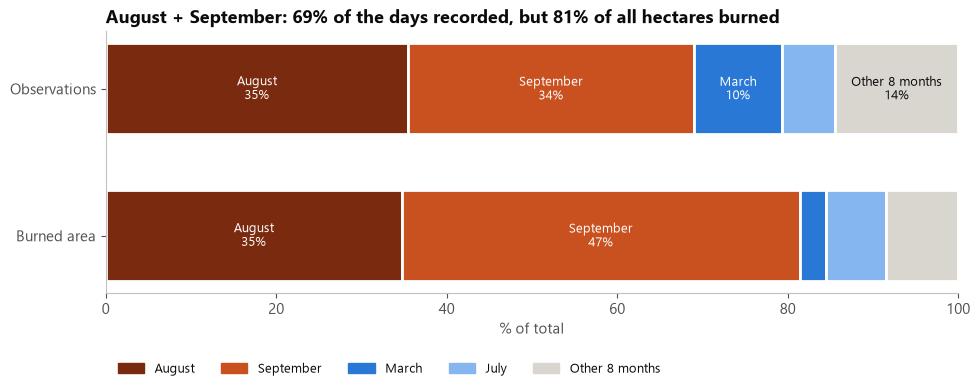

In [9]:
grp = df.assign(grp=np.select([df.month == "aug", df.month == "sep", df.month == "mar", df.month == "jul"],
                              ["August", "September", "March", "July"], "Other 8 months"))
order = ["August", "September", "March", "July", "Other 8 months"]
share_obs  = grp["grp"].value_counts(normalize=True).reindex(order) * 100
share_area = grp.groupby("grp")["area"].sum().reindex(order) / df["area"].sum() * 100
share_tbl = pd.DataFrame({"% of observations": share_obs, "% of burned area": share_area}).round(1)
print(share_tbl)

seg_colors = ["#7a2a0e", "#c9501f", "#2a78d6", "#86b6ef", "#d8d6cf"]
fig, ax = plt.subplots(figsize=(11, 3.4))
for row, (label, series) in enumerate([("Burned area", share_area), ("Observations", share_obs)]):
    left = 0
    for name, val, col in zip(order, series.values, seg_colors):
        ax.barh(row, val, left=left, color=col, edgecolor="white", linewidth=2, height=0.62)
        if val >= 9 and len(name) * 0.95 < val + 4:
            ax.text(left + val / 2, row, f"{name}\n{val:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if col in ("#7a2a0e", "#c9501f", "#2a78d6") else INK)
        left += val
ax.set_yticks([0, 1], ["Burned area", "Observations"])
ax.set_xlim(0, 100); ax.set_xlabel("% of total"); ax.grid(False)
ax.legend([Rectangle((0, 0), 1, 1, color=c) for c in seg_colors], order, ncol=5, loc="upper left", bbox_to_anchor=(0, -0.22), fontsize=9.5)
ax.set_title("August + September: 69% of the days recorded, but 81% of all hectares burned")
save(fig, "fig01_proportions.png")

### Viz 2 · How concentrated is the damage? (cumulative share of burned area)

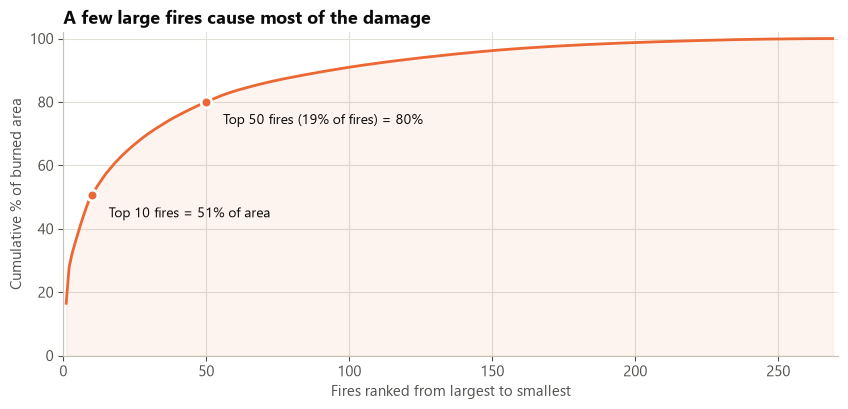

269 fires | top 10 = 50.6% | 10 fires = 50% | 50 fires = 80% of all burned area


In [10]:
fires = df.loc[df.fire == 1, "area"].sort_values(ascending=False).reset_index(drop=True)
cum = fires.cumsum() / fires.sum() * 100
top10 = cum.iloc[9]; n50 = int((cum < 50).sum() + 1); n80 = int((cum < 80).sum() + 1)
pct_fires_80 = n80 / len(fires) * 100

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(np.arange(1, len(cum) + 1), cum, color=ORANGE, lw=2)
ax.fill_between(np.arange(1, len(cum) + 1), cum, color=ORANGE, alpha=0.08)
for n, label in [(10, f"Top 10 fires = {top10:.0f}% of area"), (n80, f"Top {n80} fires ({pct_fires_80:.0f}% of fires) = 80%")]:
    ax.scatter(n, cum.iloc[n - 1], s=60, color=ORANGE, edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(label, (n, cum.iloc[n - 1]), xytext=(12, -16), textcoords="offset points", fontsize=10, color=INK)
ax.set_xlabel("Fires ranked from largest to smallest"); ax.set_ylabel("Cumulative % of burned area")
ax.set_ylim(0, 102); ax.set_xlim(0, len(cum) + 2)
ax.set_title("A few large fires cause most of the damage")
save(fig, "fig02_concentration.png")
print(f"{len(fires)} fires | top 10 = {top10:.1f}% | {n50} fires = 50% | {n80} fires = 80% of all burned area")

### Viz 3 · Treemap — nested proportions: season → month
*Rectangle size* = hectares burned; *colour* = how often an observation in that month had a fire.

In [11]:
tm = (df.groupby(["season", "month_lbl"], observed=True)
        .agg(burned_ha=("area", "sum"), fire_rate=("fire", "mean"), n=("fire", "size"))
        .reset_index())
tm = tm[tm.burned_ha > 0]
tm["fire_rate"] = (tm.fire_rate * 100).round(0)
fig_tm = px.treemap(tm, path=[px.Constant("Montesinho Park"), "season", "month_lbl"], values="burned_ha",
                    color="fire_rate", color_continuous_scale=ORANGE_SCALE, range_color=[0, 100],
                    custom_data=["n", "fire_rate"])
fig_tm.update_traces(texttemplate="<b>%{label}</b><br>%{value:,.0f} ha", marker=dict(line=dict(color="white", width=2)),
                     hovertemplate="<b>%{label}</b><br>%{value:,.1f} ha burned<br>%{customdata[0]} observations<br>Fire rate %{customdata[1]:.0f}%<extra></extra>")
fig_tm.update_layout(**PLOTLY_LAYOUT, margin=dict(t=60, l=10, r=10, b=10), height=520, width=1000,
                     title=dict(text="<b>Where the hectares went: Summer and Autumn, driven by August and September</b>", x=0.01),
                     coloraxis_colorbar=dict(title="Fire rate %", ticksuffix="%"))
fig_tm.write_image(FIG / "fig03_treemap.png", scale=2)
fig_tm.write_html(OUT / "treemap_interactive.html", include_plotlyjs="cdn")
fig_tm.show()
tm.sort_values("burned_ha", ascending=False)

,season,month_lbl,burned_ha,fire_rate,n
11,Autumn,Sep,3086.13,56.0,172
6,Summer,Aug,2297.99,54.0,182
7,Summer,Jul,459.83,56.0,32
4,Spring,Mar,206.60,34.0,53
1,Winter,Feb,125.50,50.0,20
0,Winter,Dec,119.97,100.0,9
10,Autumn,Oct,99.57,33.0,15
8,Summer,Jun,99.30,50.0,16
3,Spring,Apr,80.02,44.0,9
5,Spring,May,38.48,50.0,2


### Viz 4 · Mosaic plot — season × fire-size class
*Column width* = share of observations in that season; *segment height* = share of each fire-size class within the season.

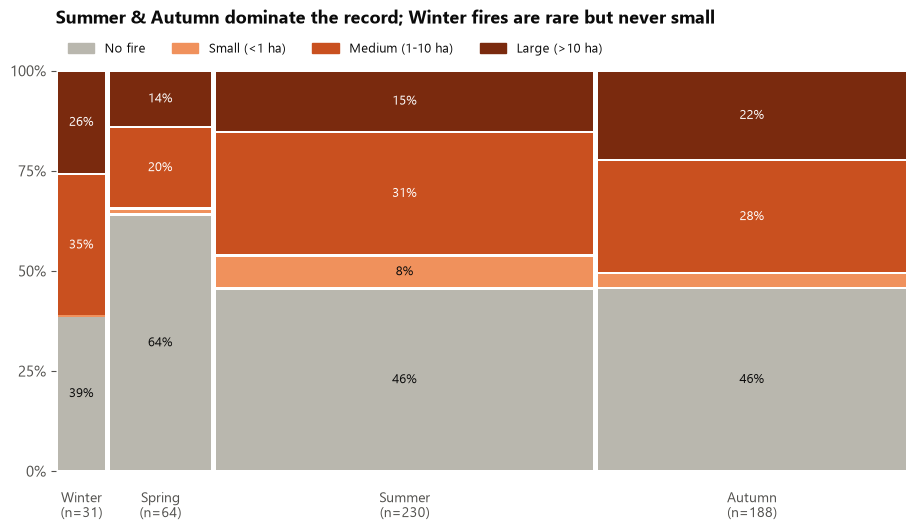

size_class,No fire,Small (<1 ha),Medium (1-10 ha),Large (>10 ha)
season,,,,
Winter,38.7,0.0,35.5,25.8
Spring,64.1,1.6,20.3,14.1
Summer,45.7,8.3,30.9,15.2
Autumn,45.7,3.7,28.2,22.3


In [12]:
ct = pd.crosstab(df["season"], df["size_class"])
col_w = ct.sum(axis=1) / ct.values.sum()
props = ct.div(ct.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(11, 5.2))
gap = 0.006
x = 0
for season in SEASON_ORDER:
    w = col_w[season]; y = 0
    for cls in SIZE_ORDER:
        h = props.loc[season, cls]
        ax.add_patch(Rectangle((x + gap / 2, y + gap / 2), w - gap, h - gap, facecolor=SIZE_COLORS[cls], edgecolor="white", lw=0))
        if h > 0.07 and w > 0.05:
            ax.text(x + w / 2, y + h / 2, f"{h*100:.0f}%", ha="center", va="center", fontsize=9.5,
                    color="white" if cls in ("Medium (1-10 ha)", "Large (>10 ha)") else INK)
        y += h
    ax.text(x + w / 2, -0.05, f"{season}\n(n={ct.loc[season].sum()})", ha="center", va="top", fontsize=10, color=INK2)
    x += w
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xticks([]); ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(False); ax.spines["left"].set_visible(False); ax.spines["bottom"].set_visible(False)
handles = [Rectangle((0, 0), 1, 1, color=SIZE_COLORS[c]) for c in SIZE_ORDER]
ax.legend(handles, SIZE_ORDER, ncol=4, loc="upper left", bbox_to_anchor=(0, 1.1), fontsize=9.5)
ax.set_title("Summer & Autumn dominate the record; Winter fires are rare but never small", pad=34)
save(fig, "fig04_mosaic.png")
(props * 100).round(1)

### Viz 5 · Small multiples — the dry-season build-up month by month
One panel per variable (each on its own scale — never a dual axis). Months with fewer than 5 observations are faded.

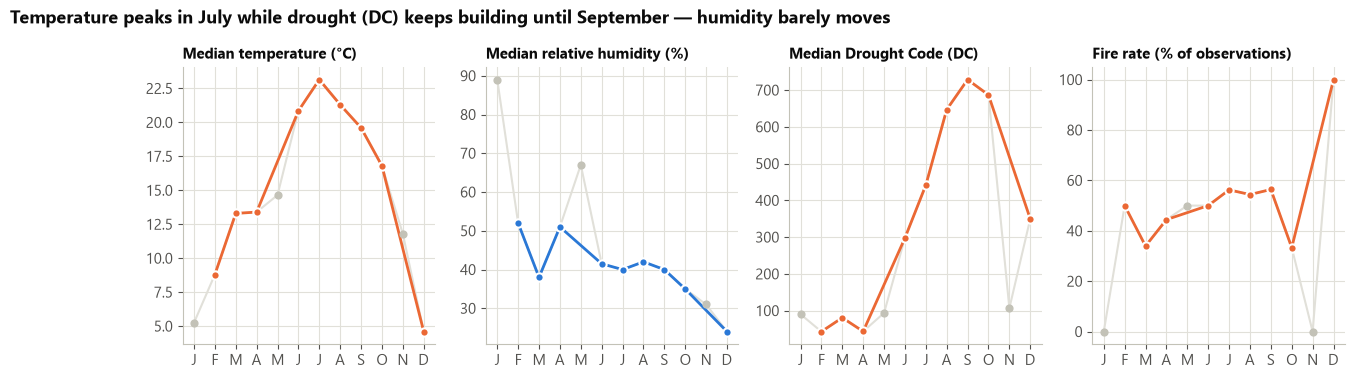

,n,temp,RH,DC,fire_rate
month_num,,,,,
1,2,5.2,89.0,90.4,0.0
2,20,8.8,52.0,43.0,50.0
3,53,13.3,38.0,80.8,34.0
4,9,13.4,51.0,43.5,44.4
5,2,14.6,67.0,93.8,50.0
6,16,20.8,41.5,297.7,50.0
7,32,23.2,40.0,441.5,56.2
8,182,21.3,42.0,647.1,54.4
9,172,19.6,40.0,728.6,56.4


In [13]:
monthly = df.groupby("month_num").agg(n=("fire", "size"), temp=("temp", "median"), RH=("RH", "median"),
                                      DC=("DC", "median"), fire_rate=("fire", "mean"))
monthly["fire_rate"] *= 100
panels = [("temp", "Median temperature (°C)"), ("RH", "Median relative humidity (%)"),
          ("DC", "Median Drought Code (DC)"), ("fire_rate", "Fire rate (% of observations)")]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharex=True)
for ax, (col, title) in zip(axes, panels):
    solid = monthly[monthly.n >= 5]
    ax.plot(monthly.index, monthly[col], color=GRID, lw=1.5, zorder=1)
    ax.plot(solid.index, solid[col], color=ORANGE if col != "RH" else BLUE, lw=2, marker="o", ms=6,
            markeredgecolor="white", markeredgewidth=1.5, zorder=2)
    ax.scatter(monthly[monthly.n < 5].index, monthly[monthly.n < 5][col], color=AXIS, s=24, zorder=2)
    ax.set_title(title, fontsize=11)
    ax.set_xticks(range(1, 13), [m[0].upper() for m in MONTHS])
fig.suptitle("Temperature peaks in July while drought (DC) keeps building until September — humidity barely moves", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.04)
save(fig, "fig05_seasonal_small_multiples.png")
monthly.round(1)

---
## Act 2 — WHY: associations among the weather variables
### Viz 6 · Correlogram

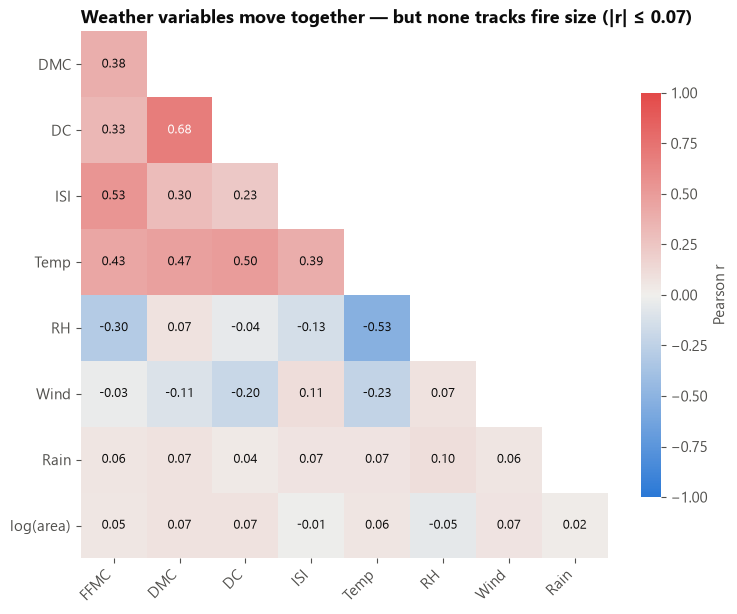

RH     -0.052
ISI    -0.009
rain    0.023
FFMC    0.047
temp    0.055
wind    0.068
DMC     0.072
DC      0.072
Name: log_area, dtype: float64

In [14]:
corr_cols = ["FFMC", "DMC", "DC", "ISI", "temp", "RH", "wind", "rain", "log_area"]
corr = df[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=0)
fig, ax = plt.subplots(figsize=(8.5, 7))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
shown = corr.mask(mask).iloc[1:, :-1]
im = ax.imshow(shown, cmap=cmap, vmin=-1, vmax=1)
for i in range(len(corr) - 1):
    for j in range(len(corr) - 1):
        if not mask[i + 1, j]:
            v = corr.iloc[i + 1, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.6 else INK)
labels = ["FFMC", "DMC", "DC", "ISI", "Temp", "RH", "Wind", "Rain", "log(area)"]
ax.set_xticks(range(len(corr) - 1), labels[:-1], rotation=45, ha="right"); ax.set_yticks(range(len(corr) - 1), labels[1:])
ax.grid(False); [s.set_visible(False) for s in ax.spines.values()]
cb = fig.colorbar(im, ax=ax, shrink=0.75); cb.outline.set_visible(False); cb.set_label("Pearson r")
ax.set_title(f"Weather variables move together — but none tracks fire size (|r| ≤ {corr['log_area'].drop('log_area').abs().max():.2f})")
save(fig, "fig06_correlogram.png")
corr["log_area"].drop("log_area").sort_values().round(3)

### Viz 7 · Scatter plot — temperature vs humidity, sized by burned area

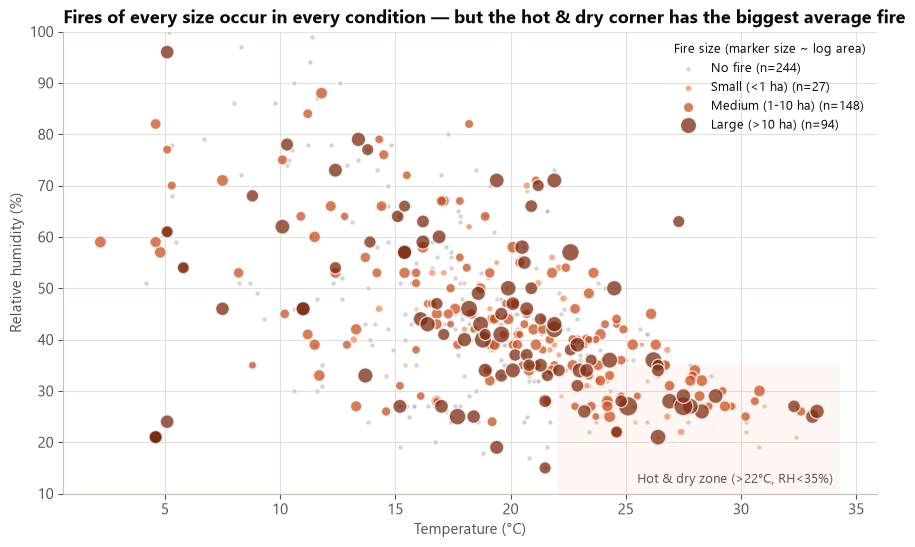

Hot & dry days: n=87, fire rate 59%, large-fire rate 22%, mean area 30.4 ha
All other days: n=426, fire rate 51%, large-fire rate 18%, mean area 9.3 ha


In [15]:
fig, ax = plt.subplots(figsize=(10.5, 6))
for cls in SIZE_ORDER:
    sub = df[df.size_class == cls]
    sizes = 14 if cls == "No fire" else 14 + sub["log_area"] * 26
    ax.scatter(sub["temp"], sub["RH"], s=sizes, color=SIZE_COLORS[cls], alpha=0.75 if cls != "No fire" else 0.6,
               edgecolor="white", linewidth=1, label=f"{cls} (n={len(sub)})")
ax.axvspan(22, df.temp.max() + 1, ymax=(35 - 10) / (100 - 10), color=ORANGE, alpha=0.06, lw=0)
ax.text(34, 11.5, "Hot & dry zone (>22°C, RH<35%)", ha="right", va="bottom", fontsize=9.5, color=INK2)
ax.set_xlabel("Temperature (°C)"); ax.set_ylabel("Relative humidity (%)"); ax.set_ylim(10, 100)
ax.legend(title="Fire size (marker size ~ log area)", loc="upper right", fontsize=9, title_fontsize=9.5)
ax.set_title("Fires of every size occur in every condition — but the hot & dry corner has the biggest average fire")
save(fig, "fig07_scatter_temp_rh.png")
hot_dry = df[(df.temp > 22) & (df.RH < 35)]
rest = df.drop(hot_dry.index)
print(f"Hot & dry days: n={len(hot_dry)}, fire rate {hot_dry.fire.mean()*100:.0f}%, "
      f"large-fire rate {(hot_dry.area > 10).mean()*100:.0f}%, mean area {hot_dry.area.mean():.1f} ha")
print(f"All other days: n={len(rest)}, fire rate {rest.fire.mean()*100:.0f}%, "
      f"large-fire rate {(rest.area > 10).mean()*100:.0f}%, mean area {rest.area.mean():.1f} ha")

### Viz 8 · Dimension reduction — PCA of the 8 weather variables

Explained variance % per component: [35.6 16.3 15.3 11.7  8.7  5.9  3.9  2.7] 
PC1+PC2 = 51.9 %


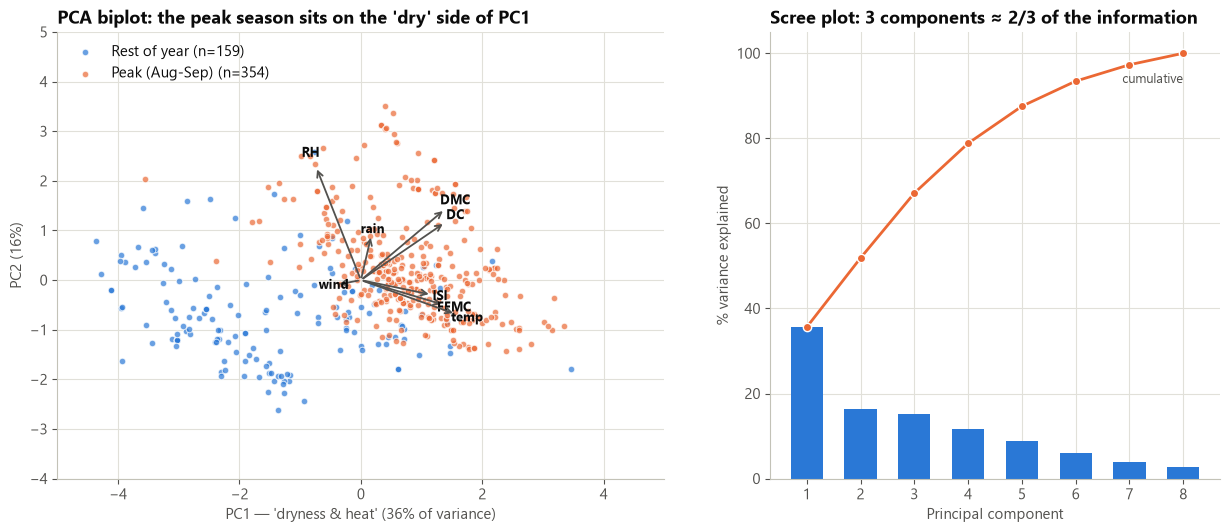

,PC1,PC2
FFMC,0.43,-0.16
DMC,0.43,0.45
DC,0.43,0.36
ISI,0.36,-0.09
temp,0.49,-0.21
RH,-0.23,0.71
wind,-0.13,-0.03
rain,0.05,0.28


In [16]:
wx = ["FFMC", "DMC", "DC", "ISI", "temp", "RH", "wind", "rain"]
Z = StandardScaler().fit_transform(df[wx])
pca = PCA().fit(Z)
if pca.components_[0][wx.index("temp")] < 0:   # orient PC1 so that hotter/drier = to the right
    pca.components_[0] *= -1
pcs = pca.transform(Z)
evr = pca.explained_variance_ratio_ * 100
print("Explained variance % per component:", evr.round(1), "\nPC1+PC2 =", evr[:2].sum().round(1), "%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1.35, 1]})
for name, col in [("Rest of year", BLUE), ("Peak (Aug-Sep)", ORANGE)]:
    m = df["period"] == name
    ax1.scatter(pcs[m, 0], pcs[m, 1], s=22, color=col, alpha=0.7, edgecolor="white", linewidth=0.8, label=f"{name} (n={m.sum()})")
load = pca.components_[:2].T * 3.2
for k, var in enumerate(wx):
    ax1.annotate("", xy=(load[k, 0], load[k, 1]), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=INK2, lw=1.3))
    ax1.text(load[k, 0] * 1.12, load[k, 1] * 1.12, var, fontsize=9.5, color=INK, ha="center", va="center", fontweight="bold")
ax1.set_xlabel(f"PC1 — 'dryness & heat' ({evr[0]:.0f}% of variance)"); ax1.set_ylabel(f"PC2 ({evr[1]:.0f}%)")
ax1.set_xlim(-5, 5); ax1.set_ylim(-4, 5)
ax1.legend(loc="upper left"); ax1.set_title("PCA biplot: the peak season sits on the 'dry' side of PC1")
ax2.bar(range(1, 9), evr, color=BLUE, width=0.6)
ax2.plot(range(1, 9), np.cumsum(evr), color=ORANGE, marker="o", ms=6, markeredgecolor="white", lw=2)
ax2.text(8, np.cumsum(evr)[-1] - 7, "cumulative", color=INK2, ha="right", fontsize=9.5)
ax2.set_xlabel("Principal component"); ax2.set_ylabel("% variance explained"); ax2.set_xticks(range(1, 9))
ax2.set_title("Scree plot: 3 components ≈ 2/3 of the information")
save(fig, "fig08_pca.png")
pd.DataFrame(pca.components_[:2].T, index=wx, columns=["PC1", "PC2"]).round(2)

### Viz 9 · Parallel sets — how conditions flow into fire outcomes

In [17]:
ps = df[["season", "ffmc_band", "temp_band", "size_class"]].astype(str)
code = df["size_class"].cat.codes
dims = [go.parcats.Dimension(values=ps["season"], label="Season", categoryorder="array", categoryarray=SEASON_ORDER),
        go.parcats.Dimension(values=ps["ffmc_band"], label="Fine-fuel dryness"),
        go.parcats.Dimension(values=ps["temp_band"], label="Temperature", categoryorder="array",
                             categoryarray=["Cool (<15C)", "Mild (15-22C)", "Hot (>22C)"]),
        go.parcats.Dimension(values=ps["size_class"], label="Fire outcome", categoryorder="array", categoryarray=SIZE_ORDER)]
cscale = [[i / 3, SIZE_COLORS[c]] for i, c in enumerate(SIZE_ORDER)]
fig_ps = go.Figure(go.Parcats(dimensions=dims, line=dict(color=code, colorscale=cscale, shape="hspline"),
                              hoveron="color", arrangement="freeform", labelfont=dict(size=14), tickfont=dict(size=12)))
fig_ps.update_layout(**PLOTLY_LAYOUT, height=520, width=1100, margin=dict(t=80, l=60, r=140, b=30),
                     title=dict(text="<b>Parallel sets: 4 in 5 observations already have dry fine fuel — dryness is the backdrop, not the trigger</b>", x=0.01))
fig_ps.write_image(FIG / "fig09_parallel_sets.png", scale=2)
fig_ps.write_html(OUT / "parallel_sets_interactive.html", include_plotlyjs="cdn")
fig_ps.show()
pd.crosstab(df["ffmc_band"], df["size_class"], normalize="index").mul(100).round(1)

size_class,No fire,Small (<1 ha),Medium (1-10 ha),Large (>10 ha)
ffmc_band,,,,
Dry fuel (FFMC>=90),46.2,5.7,29.7,18.4
Moist fuel (FFMC<90),52.8,3.8,25.5,17.9


---
## Act 3 — WHERE: hotspots on the park map (9 × 9 grid)

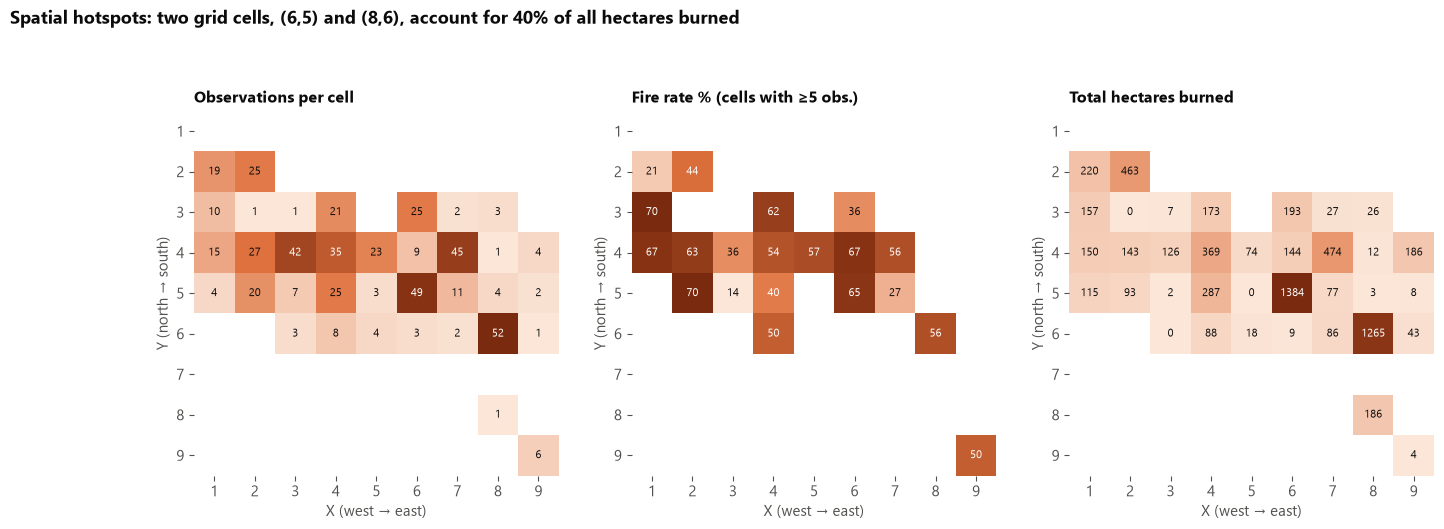

obs  fires  burned_ha
X Y                       
6 5   49     32    1384.05
8 6   52     29    1265.30
7 4   45     25     474.37
2 2   25     11     462.65
4 4   35     19     368.77
  5   25     10     287.01

In [18]:
grid_n = df.pivot_table(index="Y", columns="X", values="fire", aggfunc="size").reindex(index=range(1, 10), columns=range(1, 10))
grid_area = df.pivot_table(index="Y", columns="X", values="area", aggfunc="sum").reindex(index=range(1, 10), columns=range(1, 10))
grid_rate = df.pivot_table(index="Y", columns="X", values="fire", aggfunc="mean").reindex(index=range(1, 10), columns=range(1, 10)) * 100

cmap_o = LinearSegmentedColormap.from_list("o", ["#fbe6d8", "#e0733f", "#7a2a0e"])
fig, axes = plt.subplots(1, 3, figsize=(16, 5.4))
for ax, data, title, fmt in [(axes[0], grid_n, "Observations per cell", "{:.0f}"),
                             (axes[1], grid_rate.where(grid_n >= 5), "Fire rate % (cells with ≥5 obs.)", "{:.0f}"),
                             (axes[2], grid_area, "Total hectares burned", "{:.0f}")]:
    im = ax.imshow(data, cmap=cmap_o, origin="upper")
    for (yy, xx), v in np.ndenumerate(data.values):
        if not np.isnan(v):
            ax.text(xx, yy, fmt.format(v), ha="center", va="center", fontsize=8,
                    color="white" if v > np.nanmax(data.values) * 0.55 else INK)
    ax.set_xticks(range(9), range(1, 10)); ax.set_yticks(range(9), range(1, 10))
    ax.set_xlabel("X (west → east)"); ax.set_ylabel("Y (north → south)"); ax.grid(False)
    ax.set_title(title, fontsize=11.5)
    for s in ax.spines.values(): s.set_visible(False)
fig.suptitle(f"Spatial hotspots: two grid cells, (6,5) and (8,6), account for {(grid_area.loc[5, 6] + grid_area.loc[6, 8]) / df.area.sum() * 100:.0f}% of all hectares burned",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.02)
save(fig, "fig10_spatial_grid.png")
top_cells = (df.groupby(["X", "Y"]).agg(obs=("fire", "size"), fires=("fire", "sum"), burned_ha=("area", "sum"))
               .sort_values("burned_ha", ascending=False).head(6))
top_cells

---
## Act 4 — WHAT NEXT: a predictive early-warning model
**Target:** `fire` = 1 if any area burned. **Evaluation:** 5 × repeated stratified 5-fold cross-validation (25 fits per model)
so the score does not depend on one lucky train/test split. **Metric:** ROC-AUC (0.5 = coin flip).

In [19]:
FEATURES = ["X", "Y", "month_num", "day_num", "FFMC", "DMC", "DC", "ISI", "temp", "RH", "wind", "rain"]
Xf, yf = df[FEATURES], df["fire"]
models = {
    "Baseline (always majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Decision Tree (depth 4)": DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, class_weight="balanced", random_state=42),
    "Random Forest (300 trees)": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1),
}
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
cv_res = {}
for name, m in models.items():
    s = cross_val_score(m, Xf, yf, cv=rcv, scoring="roc_auc")
    cv_res[name] = (s.mean(), s.std())
    print(f"{name:28s} ROC-AUC {s.mean():.3f} ± {s.std():.3f}")

Baseline (always majority)   ROC-AUC 0.500 ± 0.000
Logistic Regression          ROC-AUC 0.536 ± 0.047


Decision Tree (depth 4)      ROC-AUC 0.561 ± 0.045


Random Forest (300 trees)    ROC-AUC 0.602 ± 0.044


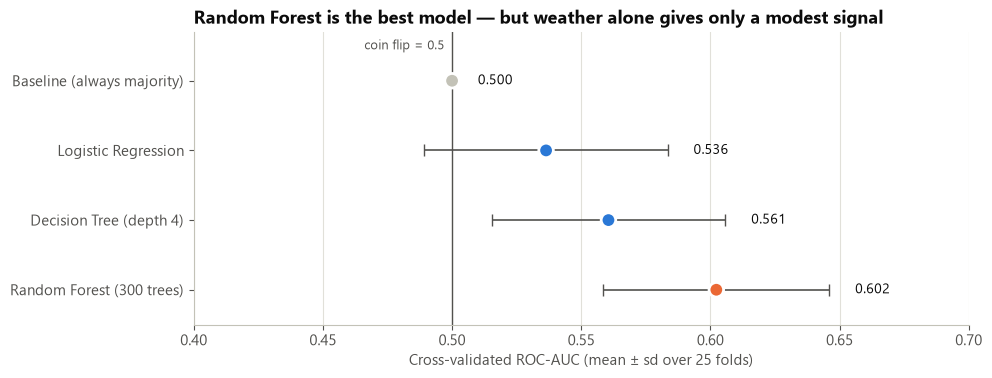

In [20]:
names = list(cv_res)
means = [cv_res[n][0] for n in names]; stds = [cv_res[n][1] for n in names]
fig, ax = plt.subplots(figsize=(10, 3.8))
cols = [AXIS, BLUE, BLUE, ORANGE]
ax.errorbar(means, range(len(names)), xerr=stds, fmt="none", ecolor=INK2, lw=1.2, capsize=4)
ax.scatter(means, range(len(names)), s=110, c=cols, edgecolor="white", linewidth=2, zorder=3)
ax.set_yticks(range(len(names)), names)
for i, (mu, sd) in enumerate(zip(means, stds)):
    ax.text(mu + sd + 0.01, i, f"{mu:.3f}", va="center", fontsize=10, color=INK)
ax.axvline(0.5, color=INK2, lw=1); ax.text(0.497, -0.45, "coin flip = 0.5", fontsize=9, color=INK2, ha="right")
ax.set_xlim(0.4, 0.7); ax.set_ylim(3.5, -0.7); ax.set_xlabel("Cross-validated ROC-AUC (mean ± sd over 25 folds)")
ax.grid(axis="y", visible=False)
ax.set_title("Random Forest is the best model — but weather alone gives only a modest signal")
save(fig, "fig11_model_comparison.png")

### Turning probabilities into risk tiers (out-of-fold predictions)
Every observation gets a probability from a model that **never saw it during training** (`cross_val_predict`).
Observations are then split into three equal-sized tiers. If the model is useful, the *High* tier should burn more often.

Out-of-fold ROC-AUC: 0.592
             n  fire_rate  large_rate  burned_ha
risk_tier                                       
Low        171       42.1        18.1     1850.9
Moderate   171       55.6        18.7     3387.8
High       171       59.6        18.1     1374.7


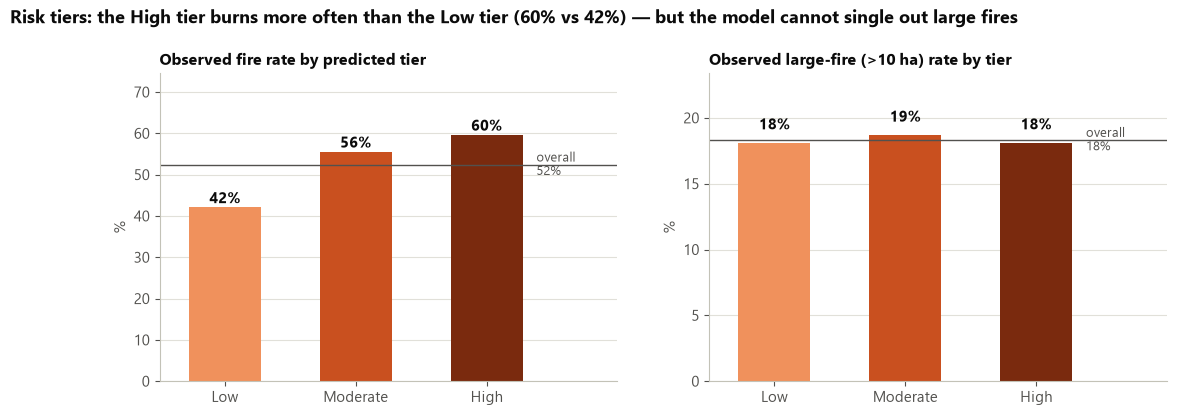

In [21]:
rf = models["Random Forest (300 trees)"]
oof = cross_val_predict(rf, Xf, yf, cv=StratifiedKFold(5, shuffle=True, random_state=42), method="predict_proba")[:, 1]
df["risk_prob"] = oof
df["risk_tier"] = pd.qcut(oof, 3, labels=["Low", "Moderate", "High"])
tier = df.groupby("risk_tier", observed=True).agg(n=("fire", "size"), fire_rate=("fire", "mean"),
                                                  large_rate=("area", lambda a: (a > 10).mean()),
                                                  burned_ha=("area", "sum"))
tier["fire_rate"] *= 100; tier["large_rate"] *= 100
print("Out-of-fold ROC-AUC:", round(roc_auc_score(yf, oof), 3))
print(tier.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
tier_cols = ["#f0915c", "#c9501f", "#7a2a0e"]
for ax, col, title, fmt in [(axes[0], "fire_rate", "Observed fire rate by predicted tier", "{:.0f}%"),
                            (axes[1], "large_rate", "Observed large-fire (>10 ha) rate by tier", "{:.0f}%")]:
    ax.bar(tier.index.astype(str), tier[col], color=tier_cols, width=0.55)
    for i, v in enumerate(tier[col]):
        ax.text(i, v + 1, fmt.format(v), ha="center", fontsize=11, fontweight="bold", color=INK)
    ax.axhline(df["fire"].mean() * 100 if col == "fire_rate" else (df.area > 10).mean() * 100, color=INK2, lw=1)
    ax.set_title(title, fontsize=11.5); ax.set_ylabel("%"); ax.grid(axis="x", visible=False)
    ax.set_ylim(0, max(tier[col]) * 1.25)
for ax, ref in [(axes[0], df.fire.mean() * 100), (axes[1], (df.area > 10).mean() * 100)]:
    ax.set_xlim(-0.5, 3.0)
    ax.text(2.35, ref, f" overall\n {ref:.0f}%", fontsize=9, color=INK2, va="center")
fig.suptitle("Risk tiers: the High tier burns more often than the Low tier (60% vs 42%) — but the model cannot single out large fires",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
save(fig, "fig12_risk_tiers.png")

### Hold-out check and what the model relies on

Hold-out ROC-AUC: 0.676
              precision    recall  f1-score   support

     No fire       0.68      0.59      0.63        61
        Fire       0.67      0.75      0.71        68

    accuracy                           0.67       129
   macro avg       0.68      0.67      0.67       129
weighted avg       0.67      0.67      0.67       129



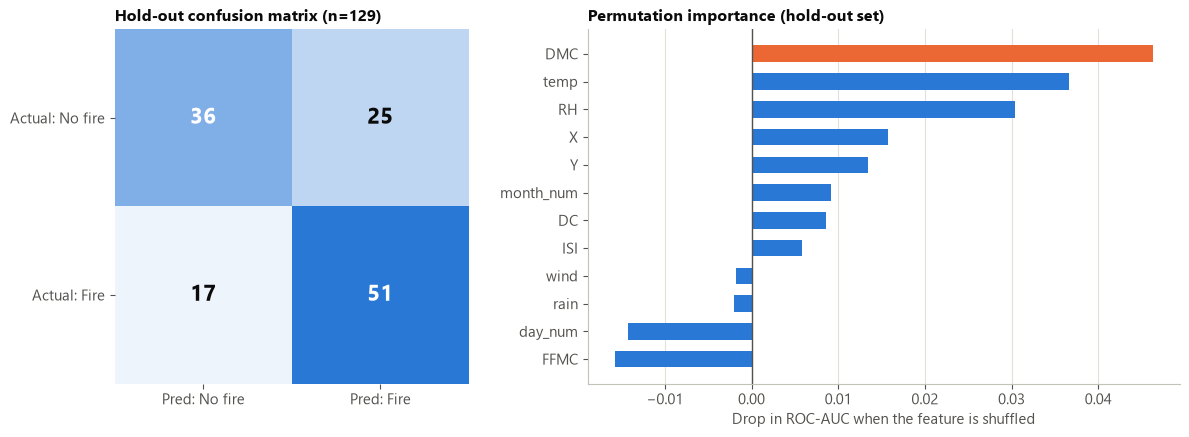

In [22]:
X_tr, X_te, y_tr, y_te = train_test_split(Xf, yf, test_size=0.25, stratify=yf, random_state=42)
rf.fit(X_tr, y_tr)
p_te = rf.predict_proba(X_te)[:, 1]; yhat = (p_te >= 0.5).astype(int)
print("Hold-out ROC-AUC:", round(roc_auc_score(y_te, p_te), 3))
print(classification_report(y_te, yhat, target_names=["No fire", "Fire"]))
cm = confusion_matrix(y_te, yhat)

pi = permutation_importance(rf, X_te, y_te, scoring="roc_auc", n_repeats=30, random_state=42)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
ax1.imshow(cm, cmap=LinearSegmentedColormap.from_list("b", ["#eef4fc", "#2a78d6"]))
for (i, j), v in np.ndenumerate(cm):
    ax1.text(j, i, str(v), ha="center", va="center", fontsize=16, fontweight="bold", color="white" if v > cm.max() * 0.6 else INK)
ax1.set_xticks([0, 1], ["Pred: No fire", "Pred: Fire"]); ax1.set_yticks([0, 1], ["Actual: No fire", "Actual: Fire"])
ax1.grid(False); [s.set_visible(False) for s in ax1.spines.values()]
ax1.set_title(f"Hold-out confusion matrix (n={len(y_te)})", fontsize=11.5)
ax2.barh(imp.index, imp.values, color=[ORANGE if v == imp.max() else BLUE for v in imp.values], height=0.6)
ax2.axvline(0, color=INK2, lw=1); ax2.grid(axis="y", visible=False)
ax2.set_xlabel("Drop in ROC-AUC when the feature is shuffled"); ax2.set_title("Permutation importance (hold-out set)", fontsize=11.5)
save(fig, "fig13_confusion_importance.png")

In [23]:
metrics = {
    **summary,
    "share_table": share_tbl.reset_index().rename(columns={"index": "group"}).to_dict(orient="records"),
    "top10_share": round(float(top10), 1), "n_fires_for_80": n80, "pct_fires_for_80": round(pct_fires_80, 1),
    "pca_evr": [round(float(v), 1) for v in evr[:3]],
    "cv_auc": {k: [round(float(v[0]), 3), round(float(v[1]), 3)] for k, v in cv_res.items()},
    "oof_auc": round(float(roc_auc_score(yf, oof)), 3),
    "holdout_auc": round(float(roc_auc_score(y_te, p_te)), 3),
    "holdout_report": classification_report(y_te, yhat, target_names=["No fire", "Fire"], output_dict=True),
    "confusion": cm.tolist(),
    "tiers": tier.round(1).reset_index().astype({"risk_tier": str}).to_dict(orient="records"),
    "importance": imp.sort_values(ascending=False).round(4).to_dict(),
    "hot_dry": {"n": int(len(hot_dry)), "fire_rate": round(hot_dry.fire.mean() * 100, 1),
                "large_rate": round((hot_dry.area > 10).mean() * 100, 1), "mean_area": round(hot_dry.area.mean(), 1)},
    "rest": {"n": int(len(rest)), "fire_rate": round(rest.fire.mean() * 100, 1),
             "large_rate": round((rest.area > 10).mean() * 100, 1), "mean_area": round(rest.area.mean(), 1)},
    "season_props": (props * 100).round(1).to_dict(orient="index"),
    "ffmc_dry_share": round((df.FFMC >= 90).mean() * 100, 1),
    "top_cells": top_cells.reset_index().to_dict(orient="records"),
    "corr_with_log_area": corr["log_area"].drop("log_area").round(3).to_dict(),
    "monthly": monthly.round(1).reset_index().to_dict(orient="records"),
}
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=str))
df.to_csv("data/forestfires_clean.csv", index=False)
print("Saved outputs/metrics.json and data/forestfires_clean.csv")

Saved outputs/metrics.json and data/forestfires_clean.csv


---
## Insights & actionable recommendations

| # | What the data shows | What the agency should do |
|---|---|---|
| 1 | **August–September** hold 69% of observations and **81% of burned hectares** (Viz 1, 3). | Concentrate crews, patrols and aerial surveillance in Aug–Sep; schedule leave and maintenance outside this window. |
| 2 | Damage is **highly concentrated** — the 10 largest fires ≈ **half** of all burned area (Viz 2). | Plan for *fast initial attack*: the goal is to stop the few fires that become large, not to treat every fire equally. |
| 3 | Temperature peaks in July and the **Drought Code keeps rising until September** (median DC ≈ 650–730 in Aug–Sep vs < 100 in spring); temperature and the drought codes move together (Viz 5, 6, 8). | Use the Fire Weather Index codes (DC, DMC) as a seasonal readiness trigger — e.g. raise readiness when DC passes ~600. |
| 4 | **Hot & dry days** (>22 °C, RH <35%) produce bigger fires on average (Viz 7). | On hot & dry forecast days, pre-position water tenders and restrict public access / campfires. |
| 5 | Fine fuel is dry (FFMC ≥ 90) on **79%** of days in the record (Viz 9) — dryness alone does not decide the outcome. | Do not rely on one index; combine weather with location and human-activity information (ignitions are often human). |
| 6 | A few **grid cells** are persistent hotspots (Viz 10). | Install watch-towers / cameras and fuel breaks in those cells first. |
| 7 | The Random Forest gives a **modest but real** signal (CV ROC-AUC ≈ 0.60); its High tier burns more often (60% vs 42%), but tiers do **not** separate large fires (≈18% in every tier) (Viz 11–12). | Use the model for *ranking days into risk tiers*, not as a yes/no alarm; improve it by adding ignition sources (roads, tourism, lightning). |

**Honest limitation:** weather explains *when* fire danger is high, but not *which exact plot* will burn on a given day.
This matches the original study (Cortez & Morais, 2007), which also found fire size hard to predict from weather alone.